# Introduction to Image Data with Python

Using matplotlib and OpenCV!

[Watch the youtube video here](https://youtu.be/kSqxn6zGE0c) that goes along with this notebook!

<table><tr>    
<td> 
  <p align="center" style="padding: 10px">
    <img alt="Forwarding" src="https://blueorange.digital/wp-content/uploads/2019/12/logo_matplotlib.jpg" width="500">
    <br>
    <em style="color: grey"></em>
  </p> 
</td>
<td> 
  <p align="center">
    <img alt="Routing" src="https://cdn-images-1.medium.com/max/1600/1*5bSooyDhHPPSsarNzBQr1w.png" width="200">
    <br>
    <em style="color: grey"></em>
  </p> 
</td>
</tr></table>

In [1]:
import pandas as pd
import numpy as np

from glob import glob

import cv2
import matplotlib.pylab as plt

plt.style.use('ggplot')

# Reading in Images

In [2]:
# we want to read the list of all our images and thats why we use glob
from glob import glob

# Correct path with a single 'training_set' folder level
cat_files = glob(
    "/Users/mahaahmedabujabal/PycharmProjects/PythonProject/Compute-Vision-Imaging/CVI Study/images/input/training_set/cats/*.jpg"
)

# Replace 'cats' with 'dogs' once you have a dogs folder (or check test_set / training_set)
dog_files = glob(
    "/Users/mahaahmedabujabal/PycharmProjects/PythonProject/Compute-Vision-Imaging/CVI Study/images/input/training_set/dogs/*.jpg"
)

print("Cat images count:", len(cat_files))
print("Dog images count:", len(dog_files))

Cat images count: 4000
Dog images count: 4005


In [3]:
# using both matplotlib and opencv to read images
img_mpl = plt.imread(cat_files[20])
img_cv2 = cv2.imread(cat_files[20])

img_mpl.shape, img_cv2.shape
#the shape represents (Height, Width, Channels(Weight) )

((375, 499, 3), (375, 499, 3))

In [4]:
print ("Array Type:" ,type (img_mpl))
print("pixle number:", img_mpl.max())

Array Type: <class 'numpy.ndarray'>
pixle number: 255


## Image Array
(Height, Width, Channels)

<img src="https://editor.analyticsvidhya.com/uploads/488590%20CI5wgSszZnpHu5Ip.png" alt="imgpixels" style="height: 200px; width:600px;"/>

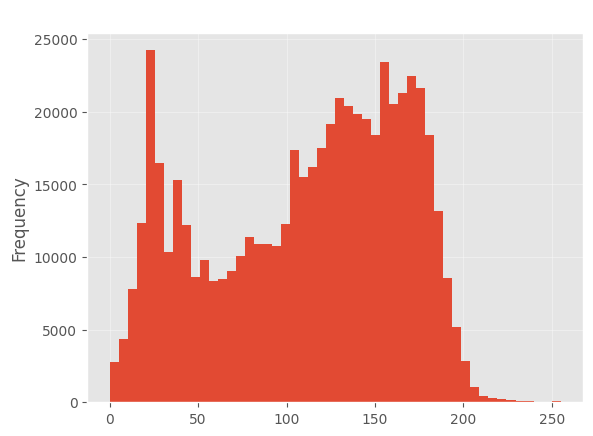

In [5]:
#To see the distribution of pixle values:
pd.Series(img_mpl.flatten()).plot(kind='hist',
                                  bins=50,
                                  title='Distribution of Pixel Values')
plt.show()

# Display Images

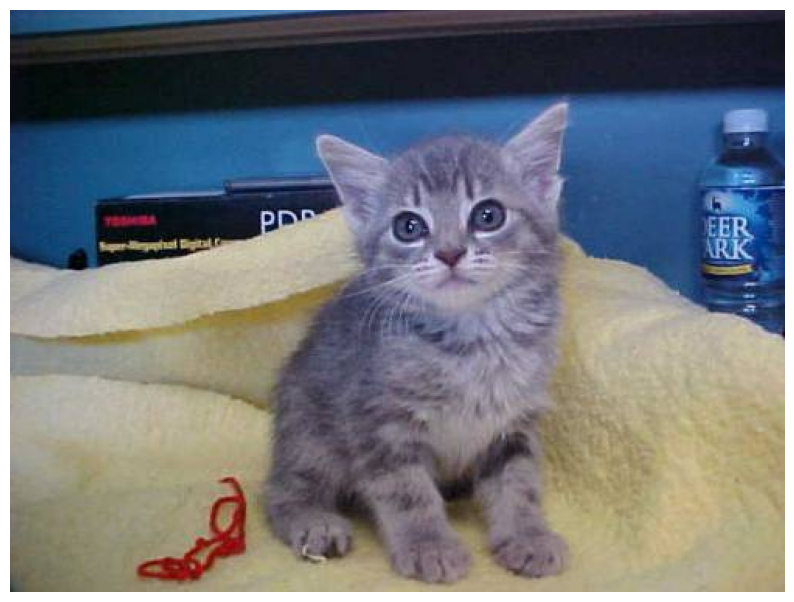

In [6]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img_mpl)
ax.axis('off')
plt.show()

# Image Channels

<img src="https://upload.wikimedia.org/wikipedia/commons/2/28/RGB_illumination.jpg" alt="Result3" style="width:300px;"/>

## RGB Channels

An RGB image has three channels: red, green, and blue. RGB channels roughly follow the color receptors in the human eye, and are used in computer displays and image scanners.

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQWv1DaHYdqXHbmwmFyFpR8CW1-Ug14EIR9PzofwoX46bo5YqENARA_XVg&s=10"/>


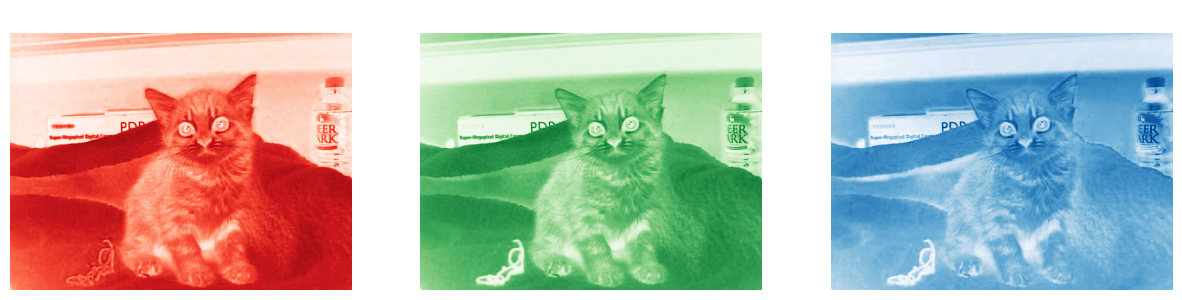

In [7]:
# Display RGB Channels of our image
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(img_mpl[:,:,0], cmap='Reds')
axs[1].imshow(img_mpl[:,:,1], cmap='Greens')
axs[2].imshow(img_mpl[:,:,2], cmap='Blues')
axs[0].axis('off')
axs[1].axis('off')
axs[2].axis('off')
axs[0].set_title('Red channel')
axs[1].set_title('Green channel')
axs[2].set_title('Blue channel')
plt.show()

# Matplotlib vs cv2 Numpy Arrays
- cv2 reads in channels as BGR
- matplotlib reads in channels as RGB


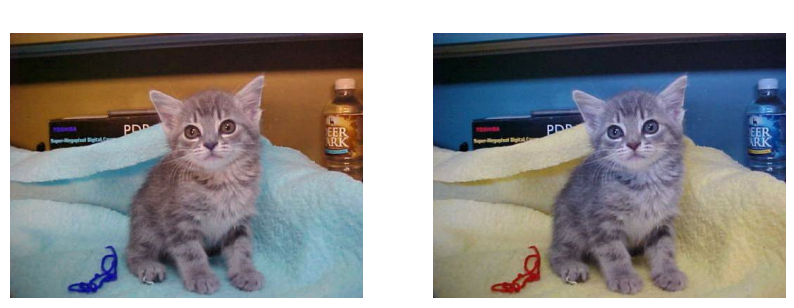

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img_cv2)
axs[1].imshow(img_mpl)
axs[0].axis('off')
axs[1].axis('off')
axs[0].set_title('CV2 Image')
axs[1].set_title('Matplotlib Image')
plt.show()

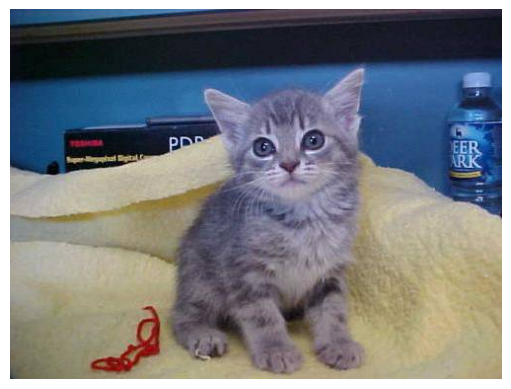

In [19]:
# Converting from BGR to RGB ( cv2 -> mlp)
img_cv2_rgb = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots()
ax.imshow(img_cv2_rgb)
ax.axis('off')
plt.show()

# Image Manipulation

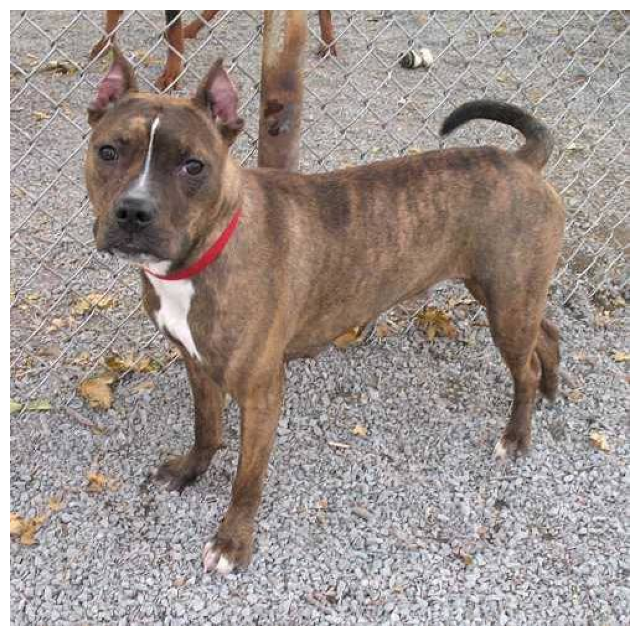

In [25]:
img = plt.imread(dog_files[4])
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img)
ax.axis('off')
plt.show()

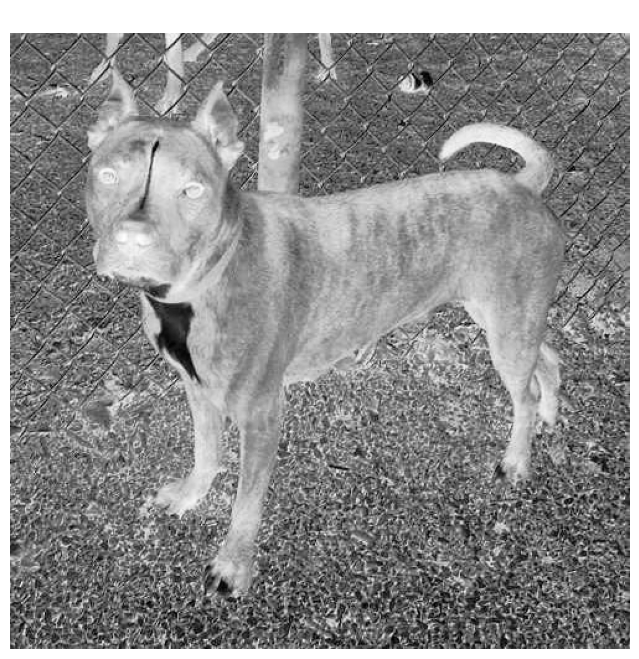

In [26]:
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_gray, cmap='Greys')
ax.axis('off')
ax.set_title('Grey Image')
plt.show()

# Resizing and Scaling

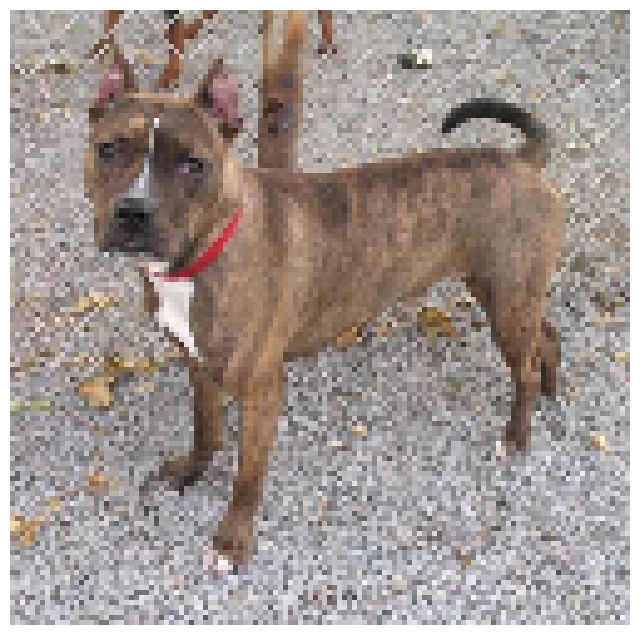

In [12]:
img_resized = cv2.resize(img, None, fx=0.25, fy=0.25)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_resized)
ax.axis('off')
plt.show()

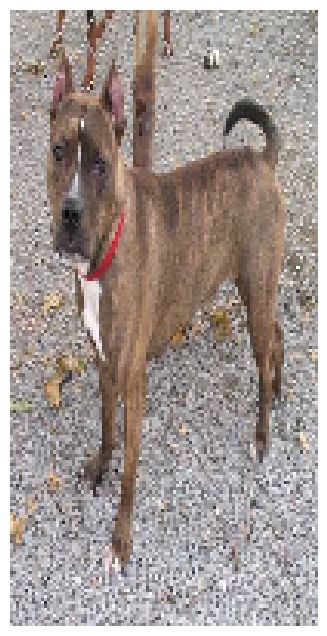

In [13]:
# Different Size
img_resize = cv2.resize(img, (100, 200))
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_resize)
ax.axis('off')
plt.show()

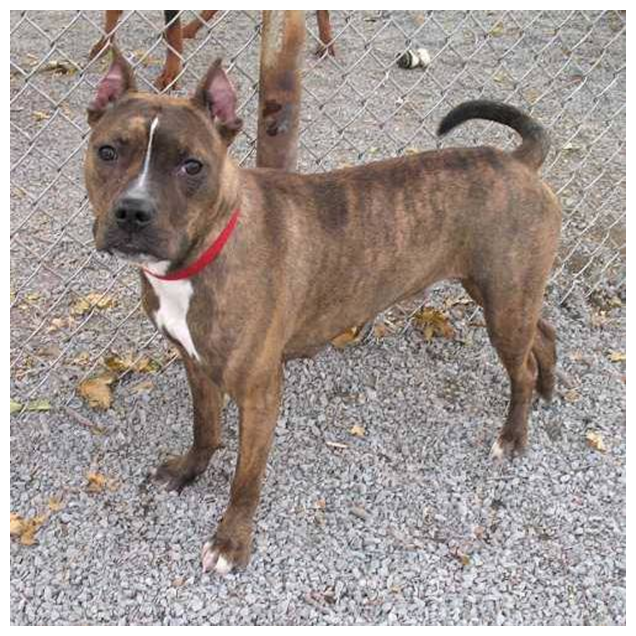

Shape of image now is: (5000, 5000, 3)


In [27]:
img_resize = cv2.resize(img, (5000, 5000), interpolation = cv2.INTER_CUBIC)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img_resize)
ax.axis('off')
plt.show()
print ("Shape of image now is:",img_resize.shape )

# CV2 Kernels
<img src="https://editor.analyticsvidhya.com/uploads/81269Capture.PNG" alt="imgpixels" style="width:400px;"/>

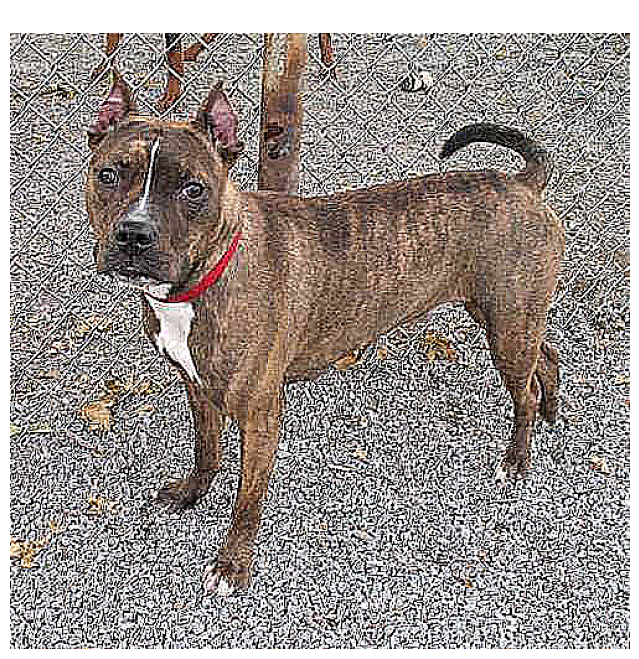

In [28]:
# Sharpen Image
kernel_sharpening = np.array([[-1,-1,-1], 
                              [-1,9,-1], 
                              [-1,-1,-1]])

sharpened = cv2.filter2D(img, -1, kernel_sharpening) #-1 is the depth

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(sharpened)
ax.axis('off')
ax.set_title('Sharpened Image')
plt.show()

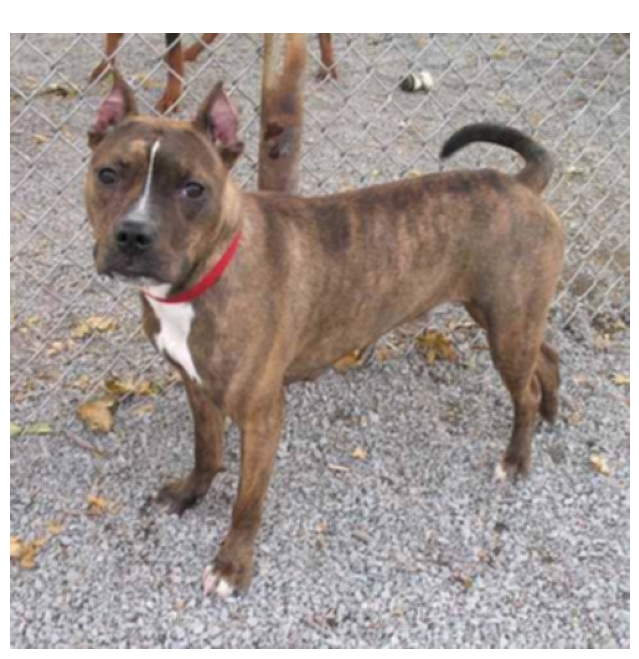

In [32]:
# Blurring the image
kernel_3x3 = np.ones((3, 3), np.float32) / 9
blurred = cv2.filter2D(img, -1, kernel_3x3)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(blurred)
ax.axis('off')
ax.set_title('Blurred Image')
plt.show()

# Save Image

In [33]:
plt.imsave('mpl_dog.png', blurred)
cv2.imwrite('cv2_dog.png', blurred)

True

# The End